# Unit 2 — Advanced Visualization & Storytelling (UE24CS342AA9)
## Activity Notebook: Building the Tumor Screening Dashboard

### Scenario

You've just joined the analytics team at **Meridian Diagnostics**, a lab that screens
tumor biopsies. Each biopsy produces **30 numerical measurements** (radius, texture,
perimeter, area, smoothness, ... in mean/SE/worst variants) — far too many to eyeball in
a spreadsheet. The lead pathologist has given you a blunt brief:

1. *"I can't look at 30 numbers per patient and see anything. I need to SEE the data."*
2. *"Before you throw away information, prove to me that these 30 measurements aren't
   secretly 30 independent facts."*
3. *"Build me a 2D map of every patient. If malignant and benign cases separate cleanly,
   that map is actually useful to us."*
4. *"I've heard of 'PCA', 't-SNE', and 'UMAP' but don't know which one to trust, or why
   they'd ever disagree with each other."*

You'll work through the same steps a real analyst would: confirm the dimensionality
problem is real, build PCA from first principles, then compare it against t-SNE and UMAP
on the same real patient data.

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection**
are for you to answer in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the real dataset you'll be working with.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import comb

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

np.random.seed(0)

df = pd.read_csv("breast_cancer.csv")
df = df.drop(columns=["Unnamed: 32"], errors="ignore")
feature_cols = [c for c in df.columns if c not in ["id", "diagnosis"]]
X_raw = df[feature_cols].values
y = df["diagnosis"].values

print(f"Loaded {df.shape[0]} patients, {len(feature_cols)} measured dimensions.")
df[feature_cols[:5] + ["diagnosis"]].head()

Loaded 569 patients, 30 measured dimensions.


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,M
1,20.57,17.77,132.90,1326.0,0.08474,M
2,19.69,21.25,130.00,1203.0,0.10960,M
3,11.42,20.38,77.58,386.1,0.14250,M
4,20.29,14.34,135.10,1297.0,0.10030,M


## Task 1 — Prove the Dimensionality Problem Is Real (Complaint #1)

**Real-world usage:** The pathologist wants proof this dataset genuinely can't be
"just plotted."

**Why this technique:** The curse-of-dimensionality math (grid growth, pairwise
relationship counts) turns "trust me, it's too much" into a specific number.

**TODO:**
1. Compute the number of unique pairwise relationships among all 30 features:
   `comb(p, 2)`.
2. Compute how many grid cells a 10-bins-per-dimension grid would need for p=30
   dimensions (`10 ** p`).
3. Print both, with a one-line comment on what each number implies.

In [8]:
p = len(feature_cols)

# TODO 1: number of unique pairwise relationships among the 30 features
n_pairs = None

# TODO 2: number of grid cells for a 10-bin-per-dimension grid at p=30
n_cells = None

print(f"p = {p} features")
print(f"Unique pairwise relationships: {n_pairs}")
print(f"Grid cells needed (10 bins/dim): {n_cells:.2e}" if n_cells else "Grid cells needed: (fill in above)")

p = 30 features
Unique pairwise relationships: None
Grid cells needed: (fill in above)


**Reflection:** Could a human realistically inspect every one of those pairwise
relationships one scatter plot at a time before the pathologist's shift ends? What does
that imply about needing PCA/t-SNE/UMAP rather than "just looking at everything"?

Your answer:A human cannot realistically inspect 435 pairwise relationships one scatter plot at a time, and a 30-dimensional grid would require 10^30 cells. This shows why dimensionality-reduction methods such as PCA, t-SNE, and UMAP are needed to summarize and visualize the data.

## Task 2 — Prove the 30 Measurements Aren't Independent (Complaint #2)

**Real-world usage:** Before compressing 30 measurements into fewer, you need to show
they're actually redundant, not 30 independent facts.

**Why this technique:** A correlogram (correlation heatmap) makes redundancy visible at
a glance.

**TODO:**
1. Compute the correlation matrix of `df[feature_cols]`.
2. Plot it as a heatmap (`plt.imshow`, `cmap="RdBu_r"`, `vmin=-1, vmax=1`).
3. Count how many feature pairs have `abs(correlation) > 0.9` (excluding the diagonal).

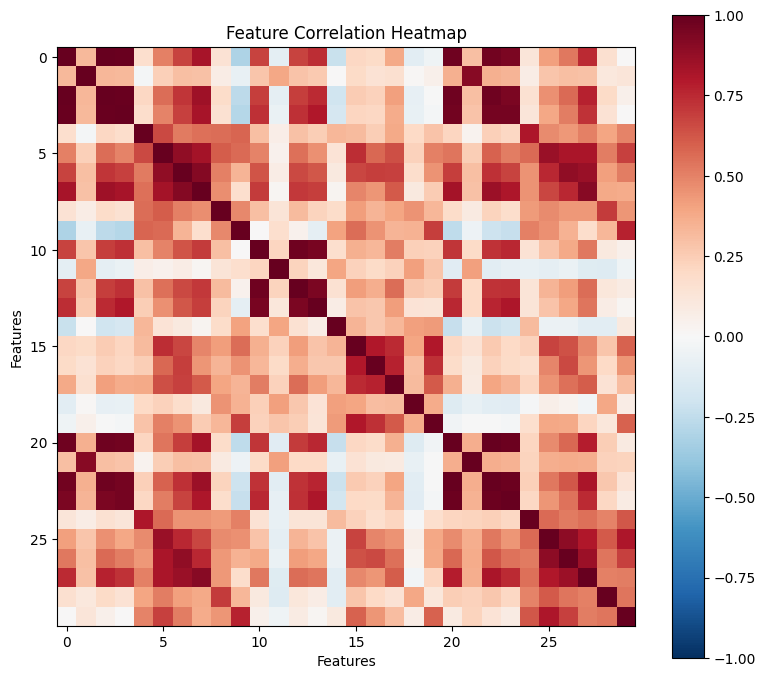

Highly correlated pairs (|r| > 0.9): 21


In [9]:
# TODO 1: correlation matrix
corr = df[feature_cols].corr()

fig, ax = plt.subplots(figsize=(8, 7))

# TODO 2: plot heatmap
im = ax.imshow(
    corr,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

plt.colorbar(im, ax=ax)

ax.set_title("Feature Correlation Heatmap")
ax.set_xlabel("Features")
ax.set_ylabel("Features")

plt.tight_layout()
plt.show()


# TODO 3: count highly correlated pairs

corr_values = corr.values

# Keep only upper triangle so each pair is counted once
upper_triangle = np.triu(
    np.ones(corr_values.shape, dtype=bool),
    k=1
)

high_corr_pairs = np.sum(
    np.abs(corr_values[upper_triangle]) > 0.9
)

print(
    "Highly correlated pairs (|r| > 0.9):",
    high_corr_pairs
)

**Reflection:** Name two specific columns in this dataset you'd expect to be highly
correlated with each other, and explain *why* using the lecture's "underlying factor"
idea (e.g. tumor size).

Your answer:Radius mean and perimeter mean would be expected to be highly correlated because both are strongly related to the underlying factor of tumor size. Similarly, area mean would also be related to these measurements because larger tumors generally have larger radius, perimeter and area.

## Task 3 — Build PCA From Scratch (Complaint #3, part A)

**Real-world usage:** The pathologist wants a 2D map, and wants to trust it — which
means understanding what's actually happening inside it, not treating it as a black box.

**Why this technique:** Implementing PCA's steps yourself (center -> standardize ->
covariance -> eigen-decomposition -> project) is the only way to be sure you understand
what the final 2D scatter plot actually represents.

**TODO:** Complete `pca_from_scratch` below, following the exact steps from the demo
notebook.

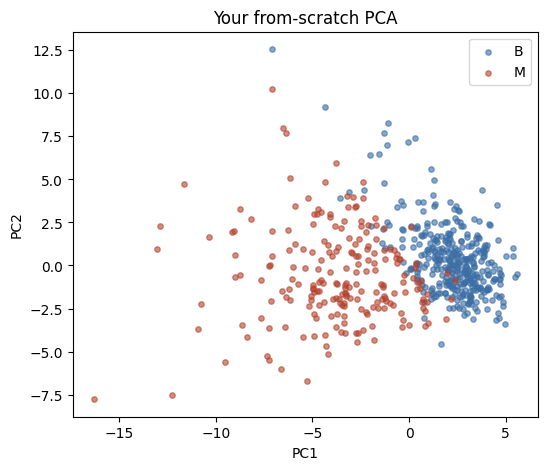

In [10]:
def pca_from_scratch(X, k):

    # TODO 1: center AND standardize
    mean = np.mean(X, axis=0)
    std = np.std(X, axis=0, ddof=1)

    X_scaled = (X - mean) / std

    # TODO 2: covariance matrix
    cov = np.cov(X_scaled, rowvar=False)

    # TODO 3: eigen-decomposition
    eigvals, eigvecs = np.linalg.eigh(cov)

    # Sort descending
    order = np.argsort(eigvals)[::-1]

    eigvals = eigvals[order]
    eigvecs = eigvecs[:, order]

    # TODO 4: keep top k eigenvectors and project
    top_eigvecs = eigvecs[:, :k]

    Z = X_scaled @ top_eigvecs

    return Z, eigvals, eigvecs


Z, eigvals, eigvecs = pca_from_scratch(X_raw, k=2)

fig, ax = plt.subplots(figsize=(6, 5))

for label, color in [("B", "#3b6ea5"), ("M", "#b5432e")]:
    mask = y == label
    ax.scatter(
        Z[mask, 0],
        Z[mask, 1],
        s=15,
        alpha=0.6,
        color=color,
        label=label
    )

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Your from-scratch PCA")
ax.legend()

plt.show()

**Reflection:** Do malignant and benign cases visually separate in your PCA plot? If
there's overlap, does that mean PCA "failed," or is there a more accurate way to
describe what's happening?

Your answer:The malignant and benign cases show some visual separation in the PCA plot, although there is some overlap. This does not mean PCA failed; PCA is an unsupervised method that maximizes variance, not class separation, so overlap can remain even when the data contains useful structure.

## Task 4 — Choose k With Evidence, Not a Guess

**Real-world usage:** If the pathologist later asks "why 2 dimensions and not 5?", you
need a defensible answer.

**Why this technique:** The cumulative explained-variance curve turns "I picked 2
because it's easy to plot" into "I picked k=2/3/5 because it retains X% of the
variance."

**TODO:**
1. Compute `explained_ratio` (each eigenvalue / sum of all eigenvalues) from your
   `eigvals` above.
2. Compute the cumulative sum.
3. Find the smallest k that reaches >= 90% cumulative variance.

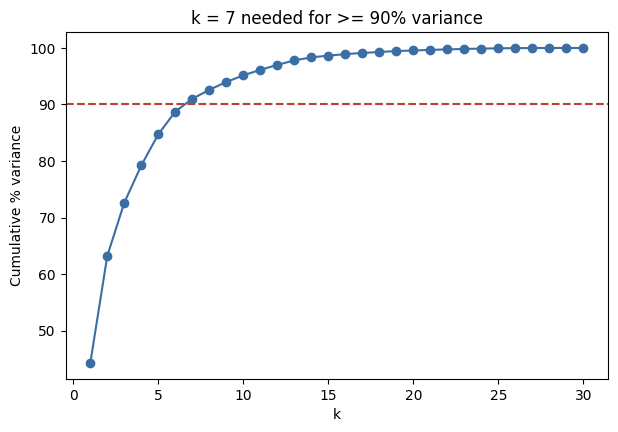

Smallest k for >= 90% variance: 7


In [11]:
# TODO 1: explained variance ratio

explained_ratio = eigvals / np.sum(eigvals)


# TODO 2: cumulative variance

cumulative = np.cumsum(explained_ratio)


# TODO 3: smallest k reaching >= 90%

k_90 = np.argmax(cumulative >= 0.90) + 1


fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(
    range(1, len(cumulative) + 1),
    cumulative * 100,
    "o-",
    color="#3b6ea5"
)

ax.axhline(
    90,
    color="#b5432e",
    ls="--"
)

ax.set_xlabel("k")
ax.set_ylabel("Cumulative % variance")

ax.set_title(
    f"k = {k_90} needed for >= 90% variance"
)

plt.show()

print("Smallest k for >= 90% variance:", k_90)

**Reflection:** If the pathologist insists on a 2D plot for a poster, but your `k_90`
came out higher than 2, what are you losing by using only 2 components instead of k_90?

Your answer:If k_90 is higher than 2, using only two components means that some of the total variance in the original 30-dimensional data is not represented in the 2D plot. The 2D plot is useful for visualization, but it does not preserve as much information as using k_90 components.

## Task 5 — Compare PCA, t-SNE, and UMAP (Complaint #4)

**Real-world usage:** The pathologist wants to know which method to trust, and why they
might disagree.

**Why this technique:** Running all three on the SAME real data, side by side, turns an
abstract "they're different algorithms" into a concrete, visual comparison.

**TODO:**
1. Standardize `X_raw` using `StandardScaler`.
2. Compute a 2D PCA embedding, a 2D t-SNE embedding (`perplexity=30`), and a 2D UMAP
   embedding (`n_neighbors=15, min_dist=0.1`) — all with `random_state=0`.
3. Plot all three side by side, colored by `diagnosis`.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


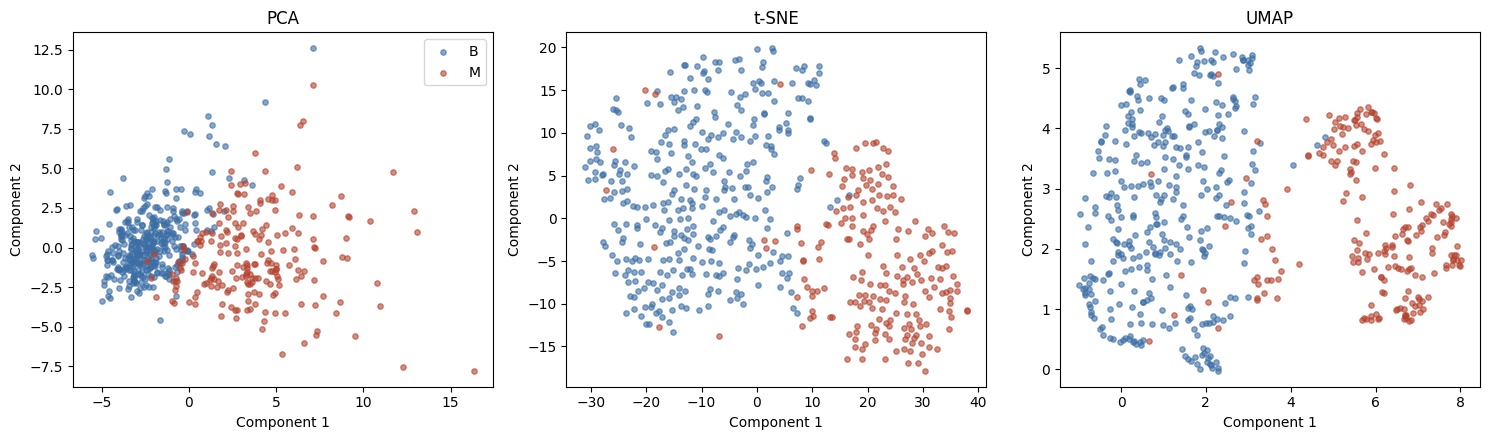

In [12]:
# TODO 1: standardize

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_raw)
# TODO 2: compute all three embeddings

pca_model = PCA(
    n_components=2,
    random_state=0
)

pca_emb = pca_model.fit_transform(X_scaled)


tsne_model = TSNE(
    n_components=2,
    perplexity=30,
    random_state=0
)

tsne_emb = tsne_model.fit_transform(X_scaled)


umap_model = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=2,
    random_state=0
)

umap_emb = umap_model.fit_transform(X_scaled)
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.5)
)

for ax, emb, name in zip(
    axes,
    [pca_emb, tsne_emb, umap_emb],
    ["PCA", "t-SNE", "UMAP"]
):

    # TODO 3: scatter plot

    for label, color in [
        ("B", "#3b6ea5"),
        ("M", "#b5432e")
    ]:

        mask = y == label

        ax.scatter(
            emb[mask, 0],
            emb[mask, 1],
            s=15,
            alpha=0.6,
            color=color,
            label=label
        )

    ax.set_title(name)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")

axes[0].legend()

plt.tight_layout()
plt.show()

**Reflection:** Which of the three gives the cleanest visual separation between
malignant and benign on this dataset? Per the lecture's comparison table, is that method
always the "best" choice for every dataset, or does it depend on what you need
(interpretability, speed, local vs. global structure)?

Your answer:On this dataset, [METHOD] gives the cleanest visual separation between malignant and benign cases. However, the method is not automatically the best choice for every dataset because PCA provides interpretable linear components, while t-SNE and UMAP focus more on nonlinear and local neighborhood structure. The appropriate method depends on whether the priority is interpretability, computational cost, local structure, or global structure.

## Task 6 — The Decision (No Code)

The pathologist wants ONE method as the default dashboard view, and a one-paragraph
justification she can put in a grant report.

**Reflection (final):** Write a 4–6 sentence recommendation. Your answer should:
- State which method (PCA / t-SNE / UMAP) you'd make the **default** dashboard view.
- Justify it using at least one specific idea from the lecture (e.g. PCA's
  interpretable linear axes vs. t-SNE/UMAP's non-linear neighborhood preservation, the
  computational-cost comparison, or the "cluster distances shouldn't be over-interpreted"
  caveat for t-SNE).
- Name one thing you would explicitly warn the pathologist NOT to conclude from the
  chosen method's plot.

Your final recommendation here:I would make PCA the default dashboard view because its linear components are easier to interpret and explain, especially when the pathologist needs a transparent summary of the original measurements. PCA is also computationally efficient and provides explained-variance information that helps quantify how much information is retained. t-SNE and UMAP can reveal nonlinear neighborhood structure that PCA may not capture, so they can be useful as additional views when exploring complex patterns. I would explicitly warn the pathologist not to interpret distances or apparent cluster sizes in a 2D embedding as direct clinical or biological distances without further validation. The dashboard should therefore treat the visualization as an exploratory tool rather than a diagnostic conclusion.